# 로지스틱 회귀 모델링

호텔 예약 취소 예측 · 담당: 강유나 · 데이터: `hotel_preprocessed.csv` (공통 전처리 결과)

## 최종 결과

| 항목 | 내용 |
| --- | --- |
| 최종 설정 | StandardScaler + log1p(치우친 5개 컬럼) + L1 규제, C=0.114, class_weight=balanced, 임계값 0.45 |
| test 성능 | **F1 0.761 · Recall 0.823 · Precision 0.708 · ROC-AUC 0.901** |
| 과적합 | 없음 (교차검증 F1 0.763 ≈ test F1 0.761) |
| 주요 변수 | 국적, 여행사, 보증금 종류, 예약~도착 기간, 특별 요청 수, 이전 취소 이력 |

## 실험 흐름

| 단계 | 실험 | CV F1 |
| --- | --- | --- |
| 3 | 기본 모델 (스케일링 없음 → 있음) | 0.706 → 0.721 |
| 4 | 과적합 확인 (C = 0.01 ~ 100) | 최대 0.722, 과적합 없음 |
| 5 | 튜닝 (Randomized 30회 → Grid) | 0.749 |
| 6 | 로그 변환 | **0.762** |
| 7 | 임계값 0.45 선택 → test 평가 | test 0.761 |

## 공통 규칙

- train / test는 CSV의 `split` 컬럼 그대로 사용 (그룹 분할)
- 교차검증·튜닝: `StratifiedGroupKFold(5, shuffle=True, random_state=0)` + `groups=groups_train`
- 인코딩·스케일링은 Pipeline 안에서 train으로만 fit
- test는 최종 모델로 한 번만 평가

## 1. 데이터 준비

공통 전처리 결과를 불러와 컬럼을 구분하고, `split` 컬럼으로 train / test를 나눕니다.

In [10]:
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1-1. 데이터 불러오기
# ------------------------------------------------------------
# 공통 전처리 결과 파일 (hotel_preprocessing.ipynb 실행 결과)
file_path = "../../hotel_preprocessed.csv"   # 프로젝트 폴더의 공통 전처리 파일

# agent(여행사 ID)는 숫자 크기에 의미가 없는 이름표라 글자로 읽음
df = pd.read_csv(file_path, dtype={"agent": str})

# ------------------------------------------------------------
# 1-2. 컬럼 구분
# ------------------------------------------------------------
# 관리용 컬럼 (모델 입력에서 제외)
#   source_row_id : 원본 데이터의 행 번호
#   group_id      : 같은 예약 묶음 번호 (교차검증 그룹 분할용)
#   split         : train / test 구분
ID_COLS = ["source_row_id", "group_id", "split"]

# 정답 컬럼 (0 = 유지, 1 = 취소)
TARGET = "is_canceled"

# 범주형 입력 10개 (원-핫 인코딩 대상)
CAT_COLS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment",
    "distribution_channel", "reserved_room_type", "deposit_type",
    "agent", "customer_type",
]

# 수치형 입력 18개 = 관리용·정답·범주형을 제외한 나머지
NUM_COLS = [c for c in df.columns if c not in ID_COLS + [TARGET] + CAT_COLS]

# ------------------------------------------------------------
# 1-3. train / test 분리
# ------------------------------------------------------------
# 전처리에서 그룹 분할로 나눠 둔 split 컬럼을 그대로 사용
# (train_test_split을 다시 하면 같은 예약 묶음이 섞여 누수가 생김)
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

# 입력(X) / 정답(y)
X_train = train[CAT_COLS + NUM_COLS]
y_train = train[TARGET]
X_test = test[CAT_COLS + NUM_COLS]
y_test = test[TARGET]

# 교차검증·튜닝 시 groups=groups_train으로 꼭 전달
groups_train = train["group_id"]

print("train:", X_train.shape, "| test:", X_test.shape)
print("범주형", len(CAT_COLS), "개 | 수치형", len(NUM_COLS), "개")

train: (95367, 28) | test: (23841, 28)
범주형 10 개 | 수치형 18 개


## 2. 로지스틱용 데이터 확인

로지스틱 회귀는 값에 가중치를 곱해 더하는 모델이라, 숫자의 **범위·치우침·겹침**에 민감합니다.

In [13]:
# ------------------------------------------------------------
# 2-1. 숫자 범위: 컬럼마다 범위 차이가 크면 스케일링이 필요
# ------------------------------------------------------------
range_table = X_train[NUM_COLS].describe().T   # .T(Transpose): 행과 열을 뒤집어 컬럼을 세로로
range_table[["min", "max", "mean"]]

,min,max,mean
lead_time,0.0,737.0,104.344679
arrival_date_year,2015.0,2017.0,2016.160318
arrival_date_week_number,1.0,53.0,27.116330
arrival_date_day_of_month,1.0,31.0,15.826418
stays_in_weekend_nights,0.0,19.0,0.925268
stays_in_week_nights,0.0,50.0,2.499156
adults,0.0,55.0,1.857928
children,0.0,10.0,0.103621
babies,0.0,10.0,0.007990
is_repeated_guest,0.0,1.0,0.030996


In [14]:
# ------------------------------------------------------------
# 2-2. 왜도(skewness): 0에 가까우면 대칭, 1 이상이면 오른쪽 꼬리가 긴 모양
#      → 많이 치우친 컬럼은 로그 변환 후보
# ------------------------------------------------------------
skewness = X_train[NUM_COLS].skew().sort_values(ascending=False)
skewness

babies                            26.891367
previous_cancellations            25.471960
previous_bookings_not_canceled    23.787477
adults                            19.647273
days_in_waiting_list              12.242651
total_guests                      10.919646
is_repeated_guest                  5.412494
children                           4.149256
has_company                        3.817802
total_nights                       3.332624
stays_in_week_nights               2.879621
stays_in_weekend_nights            1.377714
total_of_special_requests          1.356754
lead_time                          1.353178
adr                                1.034043
arrival_date_week_number          -0.002781
arrival_date_day_of_month         -0.012624
arrival_date_year                 -0.236456
dtype: float64

In [15]:
# ------------------------------------------------------------
# 2-3. 상관관계: 0.8 이상으로 겹치는 짝은 로지스틱 계수 해석을 흐림 (다중공선성)
# ------------------------------------------------------------
corr = X_train[NUM_COLS].corr()

# 상관계수가 0.8 이상인 짝만 뽑기 (자기 자신 1.0은 제외)
pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))  # 표의 위쪽 절반만 남김 (같은 짝이 두 번 나오지 않게)
        .stack()                                                  # 표 → (컬럼1, 컬럼2, 값) 목록
)
pairs[pairs.abs() >= 0.8].sort_values(ascending=False)

stays_in_week_nights  total_nights    0.940450
adults                total_guests    0.822008
dtype: float64

**확인 결과**

| 확인 | 결과 | 적용 |
| --- | --- | --- |
| 범위 | 0~1(is_repeated_guest)부터 0~737(lead_time)까지 차이가 큼 | StandardScaler (3단계에서 전후 비교) |
| 왜도 | lead_time 1.35, adr 1.03, 대부분 0인 횟수 컬럼 10 이상 | 로그 변환 후보 5개 (6단계) |
| 상관관계 | total_nights ↔ stays_in_week_nights 0.94, total_guests ↔ adults 0.82 | 파생변수 2개를 로지스틱 입력에서 제외 |

## 3. 기본 모델과 스케일링 비교

- `make_model`: 범주형은 원-핫, 수치형은 스케일링 여부를 선택하는 Pipeline
- `evaluate`: 그룹 5-fold 교차검증으로 지표 5개와 train 점수를 계산해 `results`에 쌓음

In [17]:
# ------------------------------------------------------------
# 3-1. 준비
# ------------------------------------------------------------
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# 로지스틱용 수치형 입력: 서로 겹치는 파생변수 2개 제외 (다중공선성)
LR_NUM_COLS = [c for c in NUM_COLS if c not in ["total_guests", "total_nights"]]
LR_COLS = CAT_COLS + LR_NUM_COLS

# 팀 공통 교차검증: 같은 예약 묶음이 학습/검증에 나뉘지 않게 그룹 분할
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

# 기록할 지표 5개
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]

In [18]:
# ------------------------------------------------------------
# 3-2. 모델 만드는 함수
# ------------------------------------------------------------
def make_model(use_scaler=True, C=1.0):
    preprocess = ColumnTransformer([
        # 범주형: 원-핫 (처음 보는 값은 무시, 100건 미만 값은 하나로 묶기)
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100), CAT_COLS),
        # 수치형: 스케일링 여부 선택 (passthrough = 그대로 통과)
        ("num", StandardScaler() if use_scaler else "passthrough", LR_NUM_COLS),
    ])
    model = LogisticRegression(C=C, max_iter=1000, random_state=0)
    return Pipeline([("preprocess", preprocess), ("model", model)])

In [19]:
# ------------------------------------------------------------
# 3-3. 평가 함수: 그룹 5-fold 교차검증 + train 점수(과적합 확인용)
# ------------------------------------------------------------
results = []   # 실험 결과를 계속 쌓을 리스트

def evaluate(model, name):
    scores = cross_validate(
        model, X_train[LR_COLS], y_train,
        cv=cv,
        groups=groups_train,       # 그룹 분할 (빠뜨리면 누수)
        scoring=SCORING,
        return_train_score=True,   # train 점수도 받기
        n_jobs=-1,                 # CPU 전부 사용
    )
    row = {"실험": name}
    for m in SCORING:
        row[f"train_{m}"] = scores[f"train_{m}"].mean()
        row[f"cv_{m}"] = scores[f"test_{m}"].mean()
    row["f1_gap"] = row["train_f1"] - row["cv_f1"]   # 클수록 과적합
    results.append(row)
    return pd.DataFrame([row]).round(4)

In [20]:
# ------------------------------------------------------------
# 3-4. 실험: 스케일링 없음 vs 있음
# ------------------------------------------------------------
evaluate(make_model(use_scaler=False), "기본 · 스케일링 없음")
evaluate(make_model(use_scaler=True), "기본 · 스케일링 있음")

# 결과 비교
pd.DataFrame(results)[["실험", "cv_f1", "cv_roc_auc", "cv_recall", "cv_precision", "f1_gap"]].round(4)

,실험,cv_f1,cv_roc_auc,cv_recall,cv_precision,f1_gap
0,기본 · 스케일링 없음,0.7060,0.8769,0.6374,0.7914,0.0035
1,기본 · 스케일링 있음,0.7211,0.8886,0.6578,0.7979,0.0103


**결과:** 스케일링 후 CV F1 0.706 → 0.721, AUC 0.877 → 0.889. 이후 모든 실험에 스케일링을 적용합니다.

## 4. 과적합 확인 (규제 세기 C)

C가 작을수록 규제가 강해 가중치를 작게 누릅니다. `f1_gap`(train F1 − CV F1)이 크면 과적합입니다.

In [21]:
# ------------------------------------------------------------
# 4. 과적합 확인: 규제 세기(C) 비교
#    C가 작을수록 규제가 강함 → 가중치를 작게 눌러 과적합 방지
# ------------------------------------------------------------
for C in [0.01, 0.1, 10, 100]:
    evaluate(make_model(use_scaler=True, C=C), f"C={C}")

# C=1은 위의 "기본 · 스케일링 있음"과 같아서 다시 돌리지 않음
pd.DataFrame(results)[["실험", "train_f1", "cv_f1", "f1_gap", "cv_roc_auc"]].round(4)

,실험,train_f1,cv_f1,f1_gap,cv_roc_auc
0,기본 · 스케일링 없음,0.7096,0.7060,0.0035,0.8769
1,기본 · 스케일링 있음,0.7313,0.7211,0.0103,0.8886
2,C=0.01,0.7155,0.7124,0.0030,0.8872
3,C=0.1,0.7297,0.7214,0.0083,0.8892
4,C=10,0.7310,0.7215,0.0094,0.8883
5,C=100,0.7312,0.7207,0.0105,0.8883


**결과:** C = 0.01 ~ 100에서 `f1_gap`이 모두 0.011 이하로 과적합은 없었습니다. C=0.01은 규제가 너무 강해 CV F1이 0.712로 떨어졌고(과소적합), C ≥ 0.1에서는 0.721 근처에서 멈췄습니다.

## 5. 하이퍼파라미터 튜닝

RandomizedSearchCV로 넓게 찾고, 최적값 주변을 GridSearchCV로 다시 확인합니다. 기준 지표는 F1입니다.

In [ ]:
# ------------------------------------------------------------
# 5-1. RandomizedSearchCV: 넓은 범위에서 30번 무작위로 찾기
# ------------------------------------------------------------
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from scipy.stats import loguniform

# Pipeline 안의 모델 파라미터는 "model__파라미터" 형식으로 이름 붙임
param_dist = {
    "model__C": loguniform(0.01, 100),            # 0.01~100 사이를 로그 간격으로 고르게
    "model__penalty": ["l1", "l2"],               # L1: 필요 없는 가중치를 0으로 / L2: 작게 누름
                                                  # (scikit-learn 1.8부터 l1_ratio 권장 경고가 뜨지만 결과는 같음)
    "model__class_weight": [None, "balanced"],    # balanced: 적은 쪽(취소)에 가중치를 더 줌
    "model__solver": ["liblinear"],               # L1과 L2를 모두 지원하는 계산 방법
}

rand_search = RandomizedSearchCV(
    make_model(use_scaler=True),
    param_distributions=param_dist,
    n_iter=30,                 # 무작위 조합 30개 시도 (30 × 5-fold = 150번 학습)
    scoring="f1",              # F1 기준으로 가장 좋은 조합 고르기
    cv=cv,
    random_state=0,
    n_jobs=-1,
)
rand_search.fit(X_train[LR_COLS], y_train, groups=groups_train)   # groups 꼭!

print("Randomized 최적 파라미터:", rand_search.best_params_)
print("Randomized 최고 CV F1:", round(rand_search.best_score_, 4))

c:\Users\playdata2\miniconda3\envs\agent\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\playdata2\miniconda3\envs\agent\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Randomized 최적 파라미터: {'model__C': np.float64(0.11434638743472199), 'model__class_weight': 'balanced', 'model__penalty': 'l1', 'model__solver': 'liblinear'}
Randomized 최고 CV F1: 0.7491


In [23]:
# ------------------------------------------------------------
# 5-2. GridSearchCV: Randomized 최적값 주변을 촘촘하게 찾기
#      (scikit-learn 1.8부터 penalty 대신 l1_ratio 사용: 1 = L1, 0 = L2)
# ------------------------------------------------------------
best = rand_search.best_params_
best_C = best["model__C"]

param_grid = {
    "model__C": [best_C * 0.5, best_C, best_C * 2],       # 최적 C의 절반·그대로·두 배
    "model__l1_ratio": [0, 1],                             # L2 / L1 둘 다 다시 비교
    "model__class_weight": [best["model__class_weight"]],  # Randomized 결과 그대로
    "model__solver": ["liblinear"],
}

grid_search = GridSearchCV(
    make_model(use_scaler=True),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)
grid_search.fit(X_train[LR_COLS], y_train, groups=groups_train)

print("Grid 최적 파라미터:", grid_search.best_params_)
print("Grid 최고 CV F1:", round(grid_search.best_score_, 4))

Grid 최적 파라미터: {'model__C': np.float64(0.11434638743472199), 'model__class_weight': 'balanced', 'model__l1_ratio': 1, 'model__solver': 'liblinear'}
Grid 최고 CV F1: 0.7491


In [24]:
# ------------------------------------------------------------
# 5-3. 최적 모델을 같은 평가 함수로 기록 (지표 5개 + 과적합 확인)
# ------------------------------------------------------------
best_model = grid_search.best_estimator_
evaluate(best_model, "튜닝 후 (Grid 최적)")

pd.DataFrame(results)[["실험", "cv_f1", "cv_roc_auc", "cv_recall", "cv_precision", "f1_gap"]].round(4)

,실험,cv_f1,cv_roc_auc,cv_recall,cv_precision,f1_gap
0,기본 · 스케일링 없음,0.7060,0.8769,0.6374,0.7914,0.0035
1,기본 · 스케일링 있음,0.7211,0.8886,0.6578,0.7979,0.0103
2,C=0.01,0.7124,0.8872,0.6378,0.8070,0.0030
3,C=0.1,0.7214,0.8892,0.6567,0.8004,0.0083
4,C=10,0.7215,0.8883,0.6589,0.7974,0.0094
5,C=100,0.7207,0.8883,0.6586,0.7958,0.0105
6,튜닝 후 (Grid 최적),0.7491,0.8896,0.7753,0.7248,0.0058


**결과:** C=0.114, L1, class_weight=balanced. Grid에서도 같은 값이 선택되어 최적값이 안정적입니다.
CV F1 0.721 → 0.749, Recall 0.658 → 0.775 (Precision 0.798 → 0.725). AUC는 0.889로 거의 같아, 판단 기준이 취소 쪽으로 옮겨진 효과입니다.

## 6. 추가 실험: 로그 변환

2단계에서 치우침이 컸던 5개 컬럼에 `log1p`를 적용하고, 튜닝된 파라미터 그대로 비교합니다.

In [32]:
# ------------------------------------------------------------
# 6. 추가 실험: 치우친 컬럼 로그 변환 전/후 (튜닝된 파라미터 그대로)
# ------------------------------------------------------------
from sklearn.preprocessing import FunctionTransformer

# 2단계 왜도 확인에서 찾은 후보 5개
LOG_COLS = ["lead_time", "adr", "days_in_waiting_list",
            "previous_cancellations", "previous_bookings_not_canceled"]
OTHER_NUM_COLS = [c for c in LR_NUM_COLS if c not in LOG_COLS]

def make_best_model(use_log=False):
    if use_log:
        num_steps = [
            # 로그 변환 → 스케일링 순서로 처리
            ("log", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                              ("scale", StandardScaler())]), LOG_COLS),
            ("num", StandardScaler(), OTHER_NUM_COLS),
        ]
    else:
        num_steps = [("num", StandardScaler(), LR_NUM_COLS)]

    preprocess = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100), CAT_COLS)] + num_steps
    )
    # 5단계 튜닝에서 찾은 최적 파라미터
    model = LogisticRegression(C=grid_search.best_params_["model__C"], l1_ratio=1,
                               class_weight="balanced", solver="liblinear",
                               max_iter=1000, random_state=0)
    return Pipeline([("preprocess", preprocess), ("model", model)])

evaluate(make_best_model(use_log=True), "튜닝 후 + 로그 변환")

pd.DataFrame(results)[["실험", "cv_f1", "cv_roc_auc", "cv_recall", "cv_precision", "f1_gap"]].round(4)

,실험,cv_f1,cv_roc_auc,cv_recall,cv_precision,f1_gap
0,기본 · 스케일링 없음,0.7060,0.8769,0.6374,0.7914,0.0035
1,기본 · 스케일링 있음,0.7211,0.8886,0.6578,0.7979,0.0103
2,C=0.01,0.7124,0.8872,0.6378,0.8070,0.0030
3,C=0.1,0.7214,0.8892,0.6567,0.8004,0.0083
4,C=10,0.7215,0.8883,0.6589,0.7974,0.0094
5,C=100,0.7207,0.8883,0.6586,0.7958,0.0105
6,튜닝 후 (Grid 최적),0.7491,0.8896,0.7753,0.7248,0.0058
7,튜닝 후 + 로그 변환,0.7615,0.8992,0.7955,0.7304,0.0062
8,튜닝 후 + 로그 변환,0.7615,0.8992,0.7955,0.7304,0.0062


**결과:** CV F1 0.749 → 0.762, AUC 0.890 → 0.899로 모든 지표가 올라 최종 모델에 채택합니다.

## 7. 임계값 선택과 test 평가

임계값은 test를 보기 전에 **train 교차검증 예측 확률**로 고르고, 최종 모델은 train 전체로 학습해 test를 한 번만 평가합니다.

In [36]:
# ------------------------------------------------------------
# 7-1. 임계값 고르기: train 교차검증 예측 확률로 (test는 아직 안 씀)
# ------------------------------------------------------------
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, recall_score, precision_score

final_model = make_best_model(use_log=True)

# 각 행을 "그 행을 안 본 모델"이 예측한 취소 확률 (그룹 5-fold)
cv_proba = cross_val_predict(
    final_model, X_train[LR_COLS], y_train,
    cv=cv, groups=groups_train, method="predict_proba", n_jobs=-1,
)[:, 1]

rows = []
for t in [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]:
    pred = (cv_proba >= t).astype(int)   # 확률이 t 이상이면 취소(1)로 판단
    rows.append({
        "임계값": t,
        "F1": f1_score(y_train, pred),
        "Recall": recall_score(y_train, pred),
        "Precision": precision_score(y_train, pred),
    })
threshold_table = pd.DataFrame(rows).round(4)
threshold_table

,임계값,F1,Recall,Precision
0,0.30,0.7375,0.9180,0.6162
1,0.35,0.7504,0.8950,0.6460
2,0.40,0.7584,0.8647,0.6754
3,0.45,0.7625,0.8334,0.7028
4,0.50,0.7615,0.7955,0.7303
5,0.55,0.7566,0.7532,0.7601
6,0.60,0.7470,0.7094,0.7887


In [37]:
# ------------------------------------------------------------
# 7-2. 최종 모델: train 전체로 학습 → test 한 번 평가
#      임계값 0.45는 7-1(train 교차검증)에서 미리 정함
# ------------------------------------------------------------
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

THRESHOLD = 0.45

final_model = make_best_model(use_log=True)
final_model.fit(X_train[LR_COLS], y_train)   # train 전체로 학습

test_proba = final_model.predict_proba(X_test[LR_COLS])[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)

test_result = pd.DataFrame([{
    "모델": "로지스틱 회귀 (최종)",
    "임계값": THRESHOLD,
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred),
    "recall": recall_score(y_test, test_pred),
    "f1": f1_score(y_test, test_pred),
    "roc_auc": roc_auc_score(y_test, test_proba),   # AUC는 임계값과 상관없이 확률로 계산
}]).round(4)
test_result

,모델,임계값,accuracy,precision,recall,f1,roc_auc
0,로지스틱 회귀 (최종),0.45,0.8086,0.708,0.8234,0.7614,0.9006


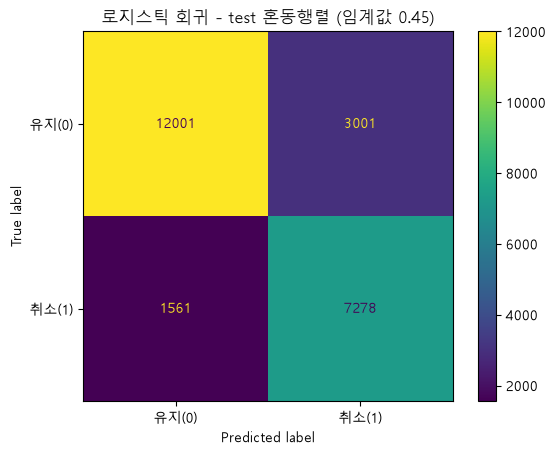

In [38]:
# 혼동행렬: 맞힌 것과 틀린 것을 개수로 보기
plt.rcParams["font.family"] = "Malgun Gothic"   # 윈도우 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False      # 마이너스 기호 깨짐 방지

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["유지(0)", "취소(1)"],
    values_format="d",
)
plt.title("로지스틱 회귀 - test 혼동행렬 (임계값 0.45)")
plt.show()

**결과:** F1이 가장 높은 임계값 0.45 선택 (CV Recall 0.833, Precision 0.703).
test: F1 0.761, Recall 0.823, Precision 0.708, ROC-AUC 0.901. 실제 취소 8,839건 중 7,278건을 미리 찾았습니다.

## 8. 주요 변수 분석

- **계수(coef_):** + 는 취소 쪽, − 는 유지 쪽. L1으로 0이 된 변수는 제외
- **permutation importance:** 컬럼 값을 섞었을 때 AUC가 떨어지는 정도. 원래 컬럼 단위라 다른 모델과 비교하기 좋음

In [39]:
# ------------------------------------------------------------
# 8-1. 주요 변수: 로지스틱 계수(coef_)
#      + 클수록 취소 쪽, − 클수록 유지 쪽 / 스케일링 후라 크기 비교 가능
# ------------------------------------------------------------
feature_names = final_model.named_steps["preprocess"].get_feature_names_out()
coefs = final_model.named_steps["model"].coef_[0]

coef_table = pd.DataFrame({"변수": feature_names, "계수": coefs})
coef_table["영향 크기"] = coef_table["계수"].abs()
coef_table = coef_table[coef_table["계수"] != 0]   # L1이 0으로 만든 변수는 제외

print("L1으로 0이 된 변수 수:", (coefs == 0).sum(), "/", len(coefs))
coef_table.sort_values("영향 크기", ascending=False).head(10).round(3)

L1으로 0이 된 변수 수: 51 / 177


,변수,계수,영향 크기
79,cat__deposit_type_Non Refund,3.056,3.056
99,cat__agent_17,2.722,2.722
88,cat__agent_134,2.161,2.161
48,cat__country_PRT,2.136,2.136
19,cat__country_AGO,2.061,2.061
152,cat__agent_9,1.975,1.975
114,cat__agent_240,1.931,1.931
104,cat__agent_191,1.484,1.484
142,cat__agent_56,1.289,1.289
78,cat__deposit_type_No Deposit,-1.212,1.212


In [40]:
# 수치형 변수만 따로 보기 (num__, log__로 시작하는 것)
# 원-핫(0/1)과 스케일링된 수치형은 계수 단위가 달라 따로 비교
num_coef = coef_table[coef_table["변수"].str.startswith(("num__", "log__"))]
num_coef.sort_values("영향 크기", ascending=False).round(3)

,변수,계수,영향 크기
164,log__previous_cancellations,1.016,1.016
161,log__lead_time,0.791,0.791
175,num__total_of_special_requests,-0.677,0.677
165,log__previous_bookings_not_canceled,-0.564,0.564
166,num__arrival_date_year,0.411,0.411
176,num__has_company,-0.244,0.244
167,num__arrival_date_week_number,0.155,0.155
170,num__stays_in_week_nights,0.121,0.121
162,log__adr,0.119,0.119
169,num__stays_in_weekend_nights,0.079,0.079


In [41]:
# ------------------------------------------------------------
# 8-2. permutation importance: 컬럼을 섞었을 때 AUC가 얼마나 떨어지나
#        (원래 컬럼 단위 + 모든 모델에 같은 방식 → 팀 비교용)
# ------------------------------------------------------------
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    final_model, X_test[LR_COLS], y_test,
    scoring="roc_auc",     # 임계값과 상관없는 AUC로 측정
    n_repeats=5,           # 5번 섞어서 평균
    random_state=0, n_jobs=-1,
)
perm_table = pd.DataFrame({
    "변수": LR_COLS,
    "중요도(AUC 감소)": perm.importances_mean,
}).sort_values("중요도(AUC 감소)", ascending=False)
perm_table.head(10).round(4)

,변수,중요도(AUC 감소)
3,country,0.0824
8,agent,0.0781
7,deposit_type,0.0685
10,lead_time,0.0436
24,total_of_special_requests,0.0322
20,previous_cancellations,0.0297
21,previous_bookings_not_canceled,0.0120
9,customer_type,0.0104
11,arrival_date_year,0.0103
25,has_company,0.0042


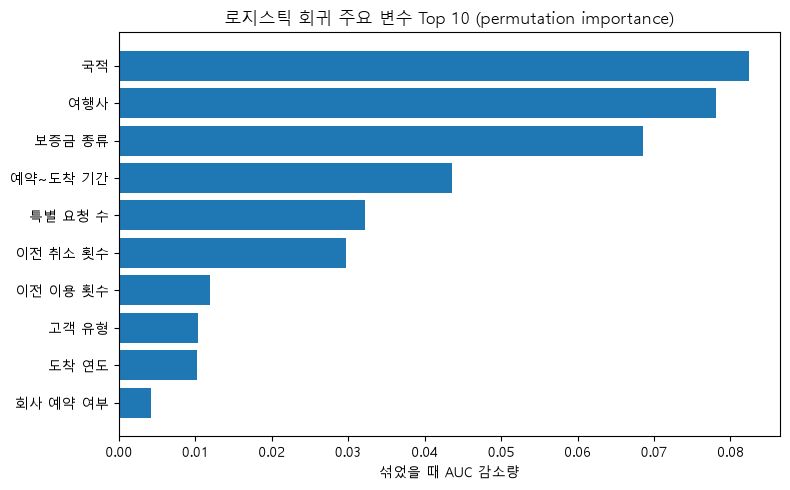

In [44]:
# ------------------------------------------------------------
# 8-3. 주요 변수 Top 10 그래프 (permutation importance)
# ------------------------------------------------------------
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

top10 = perm_table.head(10).sort_values("중요도(AUC 감소)")   # 그래프는 아래→위로 그려서 오름차순
plt.figure(figsize=(8, 5))
KOR = {
    "country": "국적", "agent": "여행사", "deposit_type": "보증금 종류",
    "lead_time": "예약~도착 기간", "total_of_special_requests": "특별 요청 수",
    "previous_cancellations": "이전 취소 횟수",
    "previous_bookings_not_canceled": "이전 이용 횟수",
    "customer_type": "고객 유형", "arrival_date_year": "도착 연도",
    "has_company": "회사 예약 여부",
}
plt.barh(top10["변수"].map(KOR), top10["중요도(AUC 감소)"], color="tab:blue")
plt.xlabel("섞었을 때 AUC 감소량")
plt.title("로지스틱 회귀 주요 변수 Top 10 (permutation importance)")
plt.tight_layout()
plt.savefig("logistic_result/logistic_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

**결과:** 두 방법 모두 보증금 종류, 여행사, 국적, 예약~도착 기간, 특별 요청 수, 이전 취소 이력이 주요 변수로 나타났습니다.
특별 요청이 많을수록, 이전 이용 이력이 있을수록 취소가 줄었습니다.

## 9. 결과 저장 (팀 공유용)

In [45]:
# ------------------------------------------------------------
# 9. 팀에 넘길 결과 저장
# ------------------------------------------------------------
pd.DataFrame(results).round(4).to_csv("logistic_result/logistic_cv_results.csv", index=False, encoding="utf-8-sig")
test_result.to_csv("logistic_result/logistic_test_result.csv", index=False, encoding="utf-8-sig")
coef_table.sort_values("영향 크기", ascending=False).round(4).to_csv(
    "logistic_result/logistic_coefficients.csv", index=False, encoding="utf-8-sig")
perm_table.round(4).to_csv("logistic_result/logistic_permutation_importance.csv", index=False, encoding="utf-8-sig")

print("저장 완료")
print("- logistic_cv_results.csv : 실험 8개 교차검증 결과")
print("- logistic_test_result.csv : 최종 모델 test 결과")
print("- logistic_coefficients.csv : 변수별 계수")
print("- logistic_permutation_importance.csv : 컬럼별 중요도")

저장 완료
- logistic_cv_results.csv : 실험 8개 교차검증 결과
- logistic_test_result.csv : 최종 모델 test 결과
- logistic_coefficients.csv : 변수별 계수
- logistic_permutation_importance.csv : 컬럼별 중요도


In [46]:
import joblib
joblib.dump(final_model, "final_model.joblib")

['final_model.joblib']